<div style="background-color: #F8F9FA; border-left: 5px solid #B8332A; padding: 22px 26px; border-radius: 6px; font-family: 'Segoe UI', Helvetica, Arial, sans-serif; color: #1F2933; box-shadow: 0 2px 6px rgba(0,0,0,0.04);">
  <div style="font-size: 11px; letter-spacing: 1.5px; text-transform: uppercase; color: #B8332A; font-weight: 700; margin-bottom: 6px;">
    Actividad 4 · Ciencia de Datos y Análisis Ambiental
  </div>
  <h1 style="margin: 0 0 10px 0; font-size: 23px; color: #102A43; font-weight: 700;">
    Trayectoria Histórica y Modelado Predictivo de las Emisiones de CO₂ per Cápita en China (1907–2025)
  </h1>
  <p style="margin: 0 0 16px 0; font-size: 14px; color: #486581; line-height: 1.5;">
    Estudio cuantitativo basado en los registros del <em>Global Carbon Budget (2026)</em> publicados por <strong>Our World in Data</strong>, evaluando la transición industrial de China y su proyección mediante modelos de regresión lineal.
  </p>
  <table style="width: 100%; border-collapse: collapse; font-size: 13px; background-color: #FFFFFF; border: 1px solid #E2E8F0;">
    <tr style="background-color: #102A43; color: #FFFFFF;">
      <th style="padding: 8px 12px; text-align: left;">Integrante</th>
      <th style="padding: 8px 12px; text-align: left;">Código / ID</th>
      <th style="padding: 8px 12px; text-align: left;">Grupo de Entrega</th>
    </tr>
    <tr style="border-bottom: 1px solid #E2E8F0;">
      <td style="padding: 8px 12px; font-weight: 600;">Santiago Rodríguez Aldana</td>
      <td style="padding: 8px 12px;">46940</td>
      <td style="padding: 8px 12px;" rowspan="2"><strong>Grupo B</strong></td>
    </tr>
    <tr>
      <td style="padding: 8px 12px; font-weight: 600;">María Catalina Franco</td>
      <td style="padding: 8px 12px;">44642</td>
    </tr>
  </table>
</div>

### 1. Configuración del Entorno y Carga de Datos
En esta primera etapa importamos las librerías científicas necesarias y definimos una estética tipográfica y cromática sobria (estilo editorial) para evitar los gráficos predeterminados. Posteriormente, cargamos el conjunto de datos **`co-emissions-per-capita.csv`** descargado directamente de la sección *Emisiones de CO₂ per cápita* de **Our World in Data**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Configuración estética global (estilo editorial)
plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 0.8

# Carga del archivo descargado de Our World in Data
ruta_archivo = 'co-emissions-per-capita.csv'
df_raw = pd.read_csv(ruta_archivo)

print(f"Dimensiones originales del dataset: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")
df_raw.head()

Dimensiones originales del dataset: 27,238 filas x 4 columnas


,Entity,Code,Year,CO₂ emissions per capita
0,Afghanistan,AFG,1949,0.001992
1,Afghanistan,AFG,1950,0.010366
2,Afghanistan,AFG,1951,0.011160
3,Afghanistan,AFG,1952,0.011009
4,Afghanistan,AFG,1953,0.012218


### 2. Limpieza, Auditoría de Calidad y Filtrado para China
Antes de modelar, auditamos la integridad de la base de datos:
1. **Estandarización de nombres de columnas:** Renombramos la variable `CO₂ emissions per capita` a `co2_per_capita` para facilitar su manipulación programática sin problemas de codificación.
2. **Diagnóstico de valores nulos y duplicados:** Verificamos si existen registros incompletos (como agregaciones regionales que carecen de código ISO-3 en la columna `Code`) y comprobamos que el subconjunto de **China (`CHN`)** cuente con una serie continua sin datos faltantes.

In [2]:
# 1. Copia de trabajo y estandarización de columnas
df = df_raw.rename(columns={
    'Entity': 'pais',
    'Code': 'codigo_iso',
    'Year': 'anio',
    'CO₂ emissions per capita': 'co2_per_capita'
}).copy()

# 2. Auditoría de valores nulos y duplicados en la base global
print("Valores nulos en dataset global:")
print(df.isnull().sum())
print(f"\nRegistros duplicados exactos: {df.duplicated().sum()}")

# 3. Filtrado específico para China (CHN) y ordenamiento cronológico
df_china = (
    df[df['codigo_iso'] == 'CHN']
    .dropna(subset=['anio', 'co2_per_capita'])
    .sort_values('anio')
    .reset_index(drop=True)
)

# 4. Resumen estadístico descriptivo de China
resumen_china = pd.DataFrame({
    'Métrica': [
        'Periodo analizado',
        'Total de observaciones (años)',
        'Mínimo histórico (1912)',
        'Mediana histórica',
        'Promedio histórico (1907–2025)',
        'Desviación estándar',
        'Máximo histórico (2025)'
    ],
    'Valor': [
        f"{df_china['anio'].min()} – {df_china['anio'].max()}",
        f"{len(df_china)} años",
        f"{df_china['co2_per_capita'].min():.4f} t/persona",
        f"{df_china['co2_per_capita'].median():.4f} t/persona",
        f"{df_china['co2_per_capita'].mean():.4f} t/persona",
        f"{df_china['co2_per_capita'].std():.4f} t/persona",
        f"{df_china['co2_per_capita'].max():.4f} t/persona"
    ]
})

display(resumen_china)

Valores nulos en dataset global:
pais                 0
codigo_iso        1151
anio                 0
co2_per_capita       0
dtype: int64

Registros duplicados exactos: 0


,Métrica,Valor
0,Periodo analizado,1907 – 2025
1,Total de observaciones (años),119 años
2,Mínimo histórico (1912),0.0399 t/persona
3,Mediana histórica,0.8131 t/persona
4,Promedio histórico (1907–2025),1.9879 t/persona
5,Desviación estándar,2.5663 t/persona
6,Máximo histórico (2025),8.7688 t/persona


### 3. Visualización Exploratoria y Contexto Internacional (2025)
De acuerdo con los registros comparativos de **Our World in Data** (donde economías europeas como Finlandia registran `5.18 t`, Bulgaria `5.04 t`, Croacia `4.99 t` e Italia `4.97 t` en 2025), existe una marcada disparidad en las emisiones individuales alrededor del mundo.

Para dimensionar la magnitud de China (`8.77 t` en 2025), contrastamos su trayectoria histórica frente a tres puntos de referencia clave:
* **Promedio Mundial (`4.74 t` en 2025):** China superó ligeramente la media global en 2005 (`4.51 t` vs. `4.50 t`) y la rebasó de forma consolidada a partir de 2006 (`4.95 t`), duplicándola en la actualidad.
* **Estados Unidos (`14.50 t` en 2025):** Históricamente el mayor emisor per cápita entre las grandes potencias, aunque con tendencia descendente desde inicios del siglo XXI.
* **Colombia (`1.80 t` en 2025):** Referente regional cuya huella per cápita representa cerca de una quinta parte de la de un habitante promedio en China.

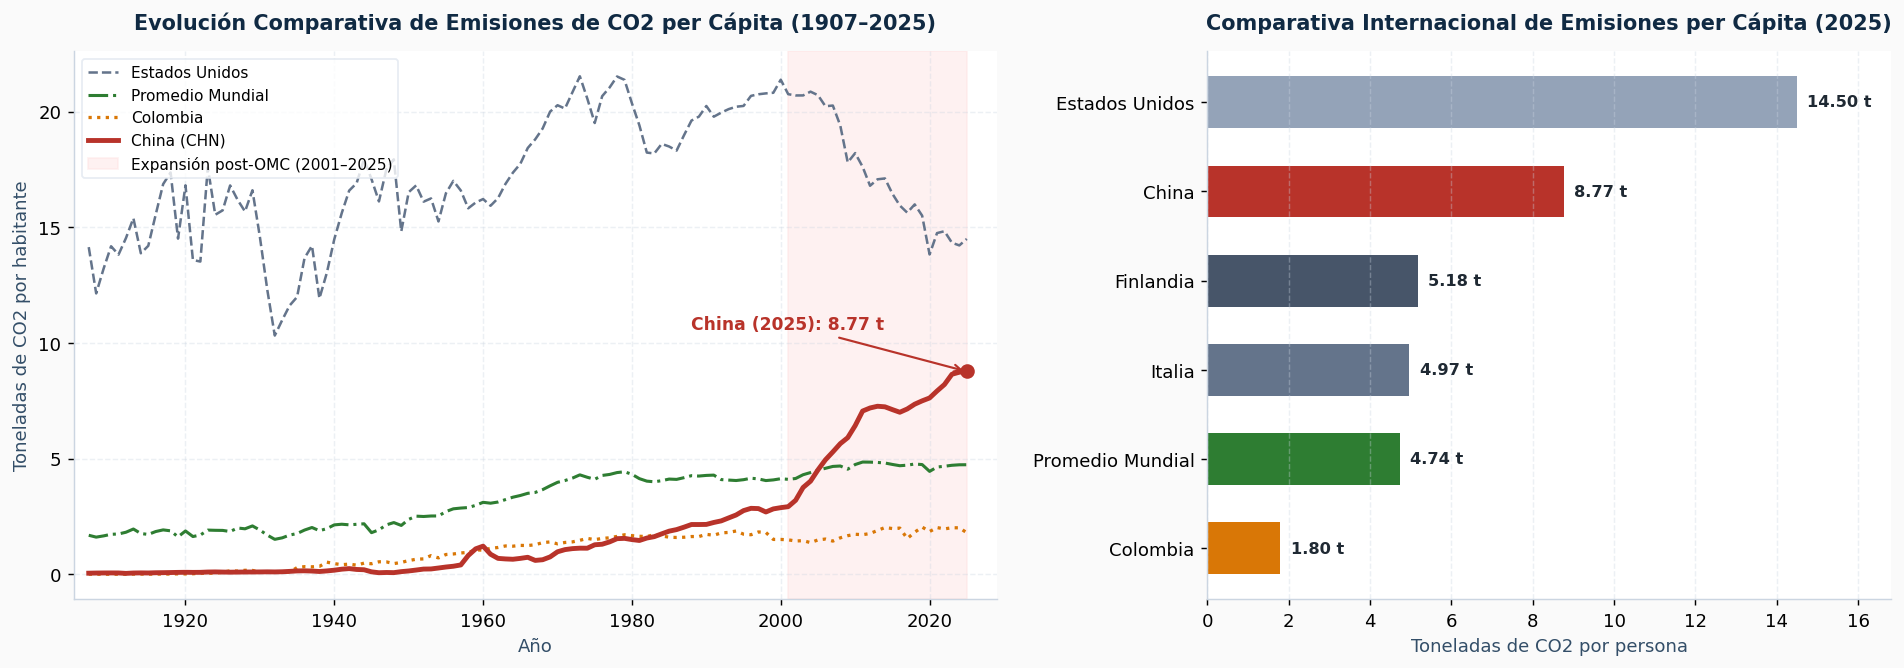

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1.35, 1]})
fig.patch.set_facecolor('#FAFAFA')

# Paleta sobria y contrastada
color_china = '#B8332A'
color_usa = '#64748B'
color_world = '#2E7D32'
color_col = '#D97706'

# --- Gráfico 1: Serie de tiempo comparativa (1907-2025) ---
ax1.set_facecolor('#FFFFFF')
for entidad, etiqueta, color, estilo, grosor in [
    ('United States', 'Estados Unidos', color_usa, '--', 1.4),
    ('World', 'Promedio Mundial', color_world, '-.', 1.7),
    ('Colombia', 'Colombia', color_col, ':', 1.8),
    ('China', 'China (CHN)', color_china, '-', 2.7)
]:
    sub = df[(df['pais'] == entidad) & (df['anio'] >= 1907)].sort_values('anio')
    ax1.plot(sub['anio'], sub['co2_per_capita'], label=etiqueta, color=color, linestyle=estilo, linewidth=grosor)

# Resaltar punto 2025 de China y periodo de aceleración
val_2025_china = df_china.loc[df_china['anio'] == 2025, 'co2_per_capita'].values[0]
ax1.scatter([2025], [val_2025_china], color=color_china, s=50, zorder=5)
ax1.annotate(f'China (2025): {val_2025_china:.2f} t', xy=(2025, val_2025_china), xytext=(1988, 10.6),
             arrowprops=dict(arrowstyle='->', color=color_china, lw=1.2),
             fontsize=9.5, fontweight='bold', color=color_china)

ax1.axvspan(2001, 2025, color='#FEE2E2', alpha=0.45, label='Expansión post-OMC (2001–2025)')
ax1.set_title('Evolución Comparativa de Emisiones de CO2 per Cápita (1907–2025)', fontsize=11.5, fontweight='bold', pad=12, color='#102A43')
ax1.set_xlabel('Año', fontsize=10, color='#334E68')
ax1.set_ylabel('Toneladas de CO2 por habitante', fontsize=10, color='#334E68')
ax1.set_xlim(1905, 2029)
ax1.grid(True, linestyle='--', alpha=0.35, color='#CBD5E1')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.legend(frameon=True, facecolor='#FFFFFF', edgecolor='#E2E8F0', fontsize=8.5, loc='upper left')

# --- Gráfico 2: Comparativa de corte transversal en 2025 ---
ax2.set_facecolor('#FFFFFF')
df_2025 = df[df['anio'] == 2025].set_index('pais')['co2_per_capita']
paises_2025 = [
    ('Estados Unidos', df_2025['United States'], '#94A3B8'),
    ('China', df_2025['China'], color_china),
    ('Finlandia', df_2025['Finland'], '#475569'),
    ('Italia', df_2025['Italy'], '#64748B'),
    ('Promedio Mundial', df_2025['World'], color_world),
    ('Colombia', df_2025['Colombia'], color_col)
]
paises_2025.reverse()
nombres = [p[0] for p in paises_2025]
valores = [p[1] for p in paises_2025]
colores_bar = [p[2] for p in paises_2025]

bars = ax2.barh(nombres, valores, color=colores_bar, height=0.58, edgecolor='none')
for bar, val in zip(bars, valores):
    ax2.text(val + 0.25, bar.get_y() + bar.get_height()/2, f'{val:.2f} t',
             va='center', ha='left', fontsize=9, fontweight='bold', color='#1F2933')

ax2.set_title('Comparativa Internacional de Emisiones per Cápita (2025)', fontsize=11.5, fontweight='bold', pad=12, color='#102A43')
ax2.set_xlabel('Toneladas de CO2 por persona', fontsize=10, color='#334E68')
ax2.set_xlim(0, 16.8)
ax2.grid(True, axis='x', linestyle='--', alpha=0.35, color='#CBD5E1')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout(pad=2.0)
plt.show()

### 4. Modelado de Datos mediante Regresión Lineal
Al observar la curva de China, resulta evidente que el fenómeno no sigue una única pendiente constante durante todo el siglo XX: hasta finales de los años noventa el crecimiento fue moderado, pero tras su adhesión a la **Organización Mundial del Comercio (OMC) en 2001**, su matriz energética e industrial experimentó un quiebre estructural.

Para lograr un análisis riguroso y evitar sesgos por subajuste (*underfitting*), entrenamos y comparamos dos modelos de **Regresión Lineal Ordinaria**:
1. **Modelo A (Serie Histórica Completa, 1907–2025):** Evalúa la tendencia lineal secular de largo plazo a lo largo de 119 años.
2. **Modelo B (Régimen Industrial Moderno, 2000–2025):** Captura la dinámica reciente de los últimos 26 años, permitiendo proyectar de forma realista el escenario hacia el año **2030** si se mantiene la trayectoria actual.

In [4]:
# Preparación de variables independientes (X) y dependientes (y)
X_hist = df_china[['anio']].values
y_hist = df_china['co2_per_capita'].values

df_china_mod = df_china[df_china['anio'] >= 2000].copy()
X_mod = df_china_mod[['anio']].values
y_mod = df_china_mod['co2_per_capita'].values

# Entrenamiento de ambos modelos lineales
modelo_hist = LinearRegression().fit(X_hist, y_hist)
modelo_mod = LinearRegression().fit(X_mod, y_mod)

# Predicciones dentro de muestra
pred_hist = modelo_hist.predict(X_hist)
pred_mod = modelo_mod.predict(X_mod)

# Proyección al año 2030
anio_proyeccion = np.array([[2030]])
proy_2030_hist = modelo_hist.predict(anio_proyeccion)[0]
proy_2030_mod = modelo_mod.predict(anio_proyeccion)[0]

# Tabla comparativa de métricas de desempeño
tabla_modelos = pd.DataFrame({
    'Modelo': [
        'Modelo A: Serie Histórica (1907–2025)',
        'Modelo B: Régimen Moderno (2000–2025)'
    ],
    'Pendiente (t/año)': [
        round(modelo_hist.coef_[0], 4),
        round(modelo_mod.coef_[0], 4)
    ],
    'Intercepto': [
        round(modelo_hist.intercept_, 2),
        round(modelo_mod.intercept_, 2)
    ],
    'R² (Bondad de ajuste)': [
        round(r2_score(y_hist, pred_hist), 4),
        round(r2_score(y_mod, pred_mod), 4)
    ],
    'RMSE (Error cuadrático)': [
        round(np.sqrt(mean_squared_error(y_hist, pred_hist)), 4),
        round(np.sqrt(mean_squared_error(y_mod, pred_mod)), 4)
    ],
    'Proyección 2030 (t/hab)': [
        round(proy_2030_hist, 2),
        round(proy_2030_mod, 2)
    ]
})

display(tabla_modelos)

,Modelo,Pendiente (t/año),Intercepto,R² (Bondad de ajuste),RMSE (Error cuadrático),Proyección 2030 (t/hab)
0,Modelo A: Serie Histórica (1907–2025),0.0638,-123.49,0.7360,1.313,6.07
1,Modelo B: Régimen Moderno (2000–2025),0.2304,-457.35,0.9225,0.501,10.35


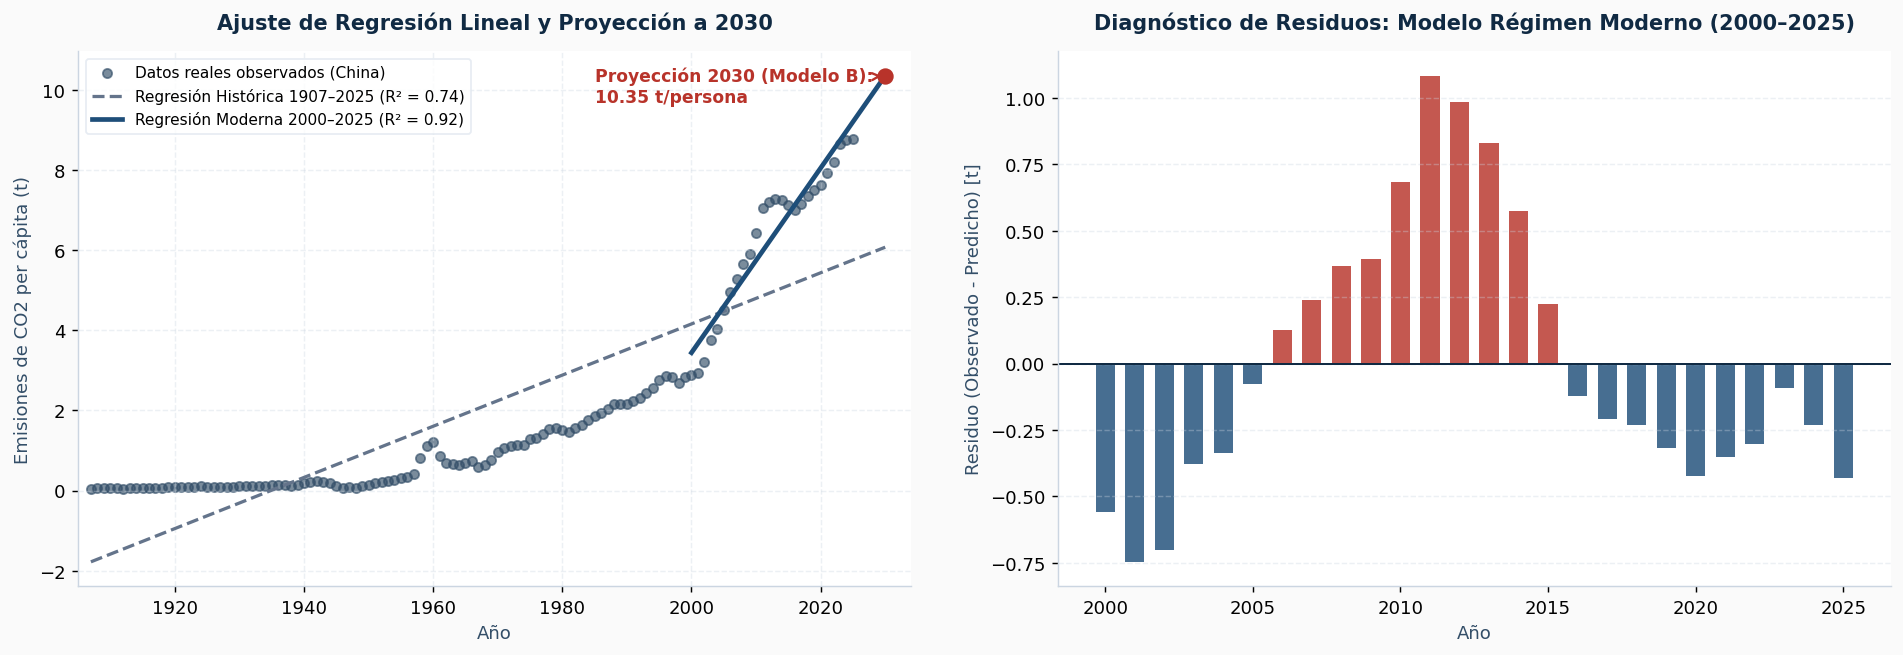

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.4))
fig.patch.set_facecolor('#FAFAFA')

# --- Panel Izquierdo: Ajuste de Regresión y Proyección 2030 ---
ax1.set_facecolor('#FFFFFF')
ax1.scatter(df_china['anio'], df_china['co2_per_capita'], color='#334E68', alpha=0.65, s=26, label='Datos reales observados (China)')

rango_hist = np.arange(1907, 2031).reshape(-1, 1)
ax1.plot(rango_hist, modelo_hist.predict(rango_hist), color='#64748B', linestyle='--', linewidth=1.8,
         label=f'Regresión Histórica 1907–2025 (R² = {r2_score(y_hist, pred_hist):.2f})')

rango_mod = np.arange(2000, 2031).reshape(-1, 1)
ax1.plot(rango_mod, modelo_mod.predict(rango_mod), color='#1E4E79', linewidth=2.6,
         label=f'Regresión Moderna 2000–2025 (R² = {r2_score(y_mod, pred_mod):.2f})')

# Punto de proyección 2030
ax1.scatter([2030], [proy_2030_mod], color='#B8332A', s=65, zorder=6)
ax1.annotate(f'Proyección 2030 (Modelo B):\n{proy_2030_mod:.2f} t/persona',
             xy=(2030, proy_2030_mod), xytext=(1985, 9.7),
             arrowprops=dict(arrowstyle='->', color='#B8332A', lw=1.3),
             fontsize=9.5, fontweight='bold', color='#B8332A')

ax1.set_title('Ajuste de Regresión Lineal y Proyección a 2030', fontsize=11.5, fontweight='bold', pad=12, color='#102A43')
ax1.set_xlabel('Año', fontsize=10, color='#334E68')
ax1.set_ylabel('Emisiones de CO2 per cápita (t)', fontsize=10, color='#334E68')
ax1.set_xlim(1905, 2034)
ax1.grid(True, linestyle='--', alpha=0.35, color='#CBD5E1')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.legend(frameon=True, facecolor='#FFFFFF', edgecolor='#E2E8F0', fontsize=8.5, loc='upper left')

# --- Panel Derecho: Análisis de Residuos del Modelo Moderno (2000–2025) ---
ax2.set_facecolor('#FFFFFF')
residuos_mod = y_mod - pred_mod
colores_res = ['#B8332A' if r > 0 else '#1E4E79' for r in residuos_mod]

ax2.bar(df_china_mod['anio'], residuos_mod, color=colores_res, alpha=0.82, width=0.65)
ax2.axhline(0, color='#102A43', linewidth=1.1, linestyle='-')
ax2.set_title('Diagnóstico de Residuos: Modelo Régimen Moderno (2000–2025)', fontsize=11.5, fontweight='bold', pad=12, color='#102A43')
ax2.set_xlabel('Año', fontsize=10, color='#334E68')
ax2.set_ylabel('Residuo (Observado - Predicho) [t]', fontsize=10, color='#334E68')
ax2.grid(True, axis='y', linestyle='--', alpha=0.35, color='#CBD5E1')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout(pad=2.0)
plt.show()

### 5. Interpretación de Resultados y Discusión Climática

A partir de la evidencia empírica extraída de *Our World in Data* y de los resultados obtenidos en los modelos estadísticos, se desprenden cuatro hallazgos fundamentales:

1. **Ruptura estructural y aceleración industrial:** Durante casi todo el siglo XX (1907–1999), las emisiones per cápita de China permanecieron por debajo de las `3.0 toneladas` anuales (con un mínimo de `0.04 t` en 1912). Sin embargo, entre 2000 y 2025 se triplicaron, alcanzando **`8.77 toneladas por persona`** en 2025. Esto refleja su consolidación como la principal potencia manufacturera global y su alta dependencia histórica del carbón para la generación eléctrica y la industria pesada.
2. **Superioridad explicativa del régimen moderno ($R^2 = 0.9225$):** Al ajustar una regresión lineal sobre toda la serie histórica (Modelo A), el coeficiente de determinación es moderado ($R^2 = 0.7360$, $\text{RMSE} = 1.31\text{ t}$) debido a la curvatura pronunciada de los últimos veinticinco años. En contraste, al modelar el periodo 2000–2025 (Modelo B), la regresión lineal explica el **92.25 % de la variabilidad** ($\text{RMSE} = 0.50\text{ t}$), demostrando un incremento promedio sostenido de **`+0.2304 toneladas por habitante cada año`**.
3. **Lectura de los residuos y desaceleración temporal (2014–2019):** El gráfico de residuos revela un superávit de emisiones entre 2011 y 2013 (impulsado por el estímulo económico poscrisis de 2008) seguido de residuos negativos entre 2015 y 2019, periodo en el que China aplicó políticas de control de calidad del aire y reestructuración industrial antes del repunte pospandemia de 2021–2025.
4. **Responsabilidad histórica frente a emisiones actuales:** Como destaca el artículo de *Our World in Data*, analizar las emisiones per cápita revela las desigualdades globales: aunque China hoy supera ampliamente el promedio mundial (`4.74 t`) y a economías europeas como Finlandia (`5.18 t`) o Italia (`4.97 t`), sigue situándose por debajo de Estados Unidos (`14.50 t`). De mantenerse la pendiente lineal de las últimas dos décadas sin un pico de descarbonización, China alcanzaría las **`10.35 toneladas per cápita` hacia 2030**, lo que subraya la importancia crítica de sus metas de neutralidad de carbono para el equilibrio climático global.